


# **Understanding Batch Normalization: A Simple Explanation**

> In the realm of deep learning, Batch Normalization (BN) emerges as a crucial technique to enhance training stability and speed. Simply put, it normalizes the input of each layer by adjusting and scaling it. This process aids in combating issues like vanishing or exploding gradients, ultimately leading to more efficient and faster convergence during training.

>To demystify the concept, I've crafted a code snippet that illustrates the working of Batch Normalization in a straightforward manner. Take a glance to unravel the simplicity behind this powerful technique.

Happy learning!



Code and dataset has taken from kaggle , but this is modified and more efficient

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

df = pd.read_csv('/content/drive/MyDrive/DL/dataset/concerticcir1.csv', header=None, names=['X','Y','class'])
df.head()

,X,Y,class
0,-0.382891,-0.090840,1.0
1,-0.020962,-0.477874,1.0
2,-0.396116,-1.289427,0.0
3,-0.618130,-0.063837,1.0
4,0.703478,-0.187038,1.0


In [4]:
# df = pd.read_csv('/content/drive/MyDrive/DL/dataset/concerticcir1.csv')
# if not use header or names with csv file
# column_name = {
#     "7.003345706103683010e-01":'X',
#     "-2.470675778972781789e-01":'Y',
#     "0.000000000000000000e+00" :'class'
# }
# df = df.rename(columns=column_name)
# df.head()

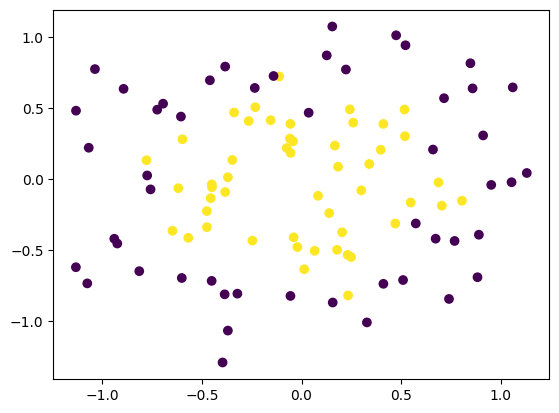

In [5]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [6]:
X= df.drop('class',axis=1).values
y=df['class'].values

In [7]:
import tensorflow
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense,BatchNormalization
from keras.utils import plot_model

# without Batch Norm

In [8]:
model = Sequential()

model.add(Dense(3,input_dim=2,activation = 'relu'))
model.add(Dense(2,activation='relu')) # one hidden layer
model.add(Dense(1,activation='sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20 (80.00 B)

 Trainable params: 20 (80.00 B)

 Non-trainable params: 0 (0.00 B)

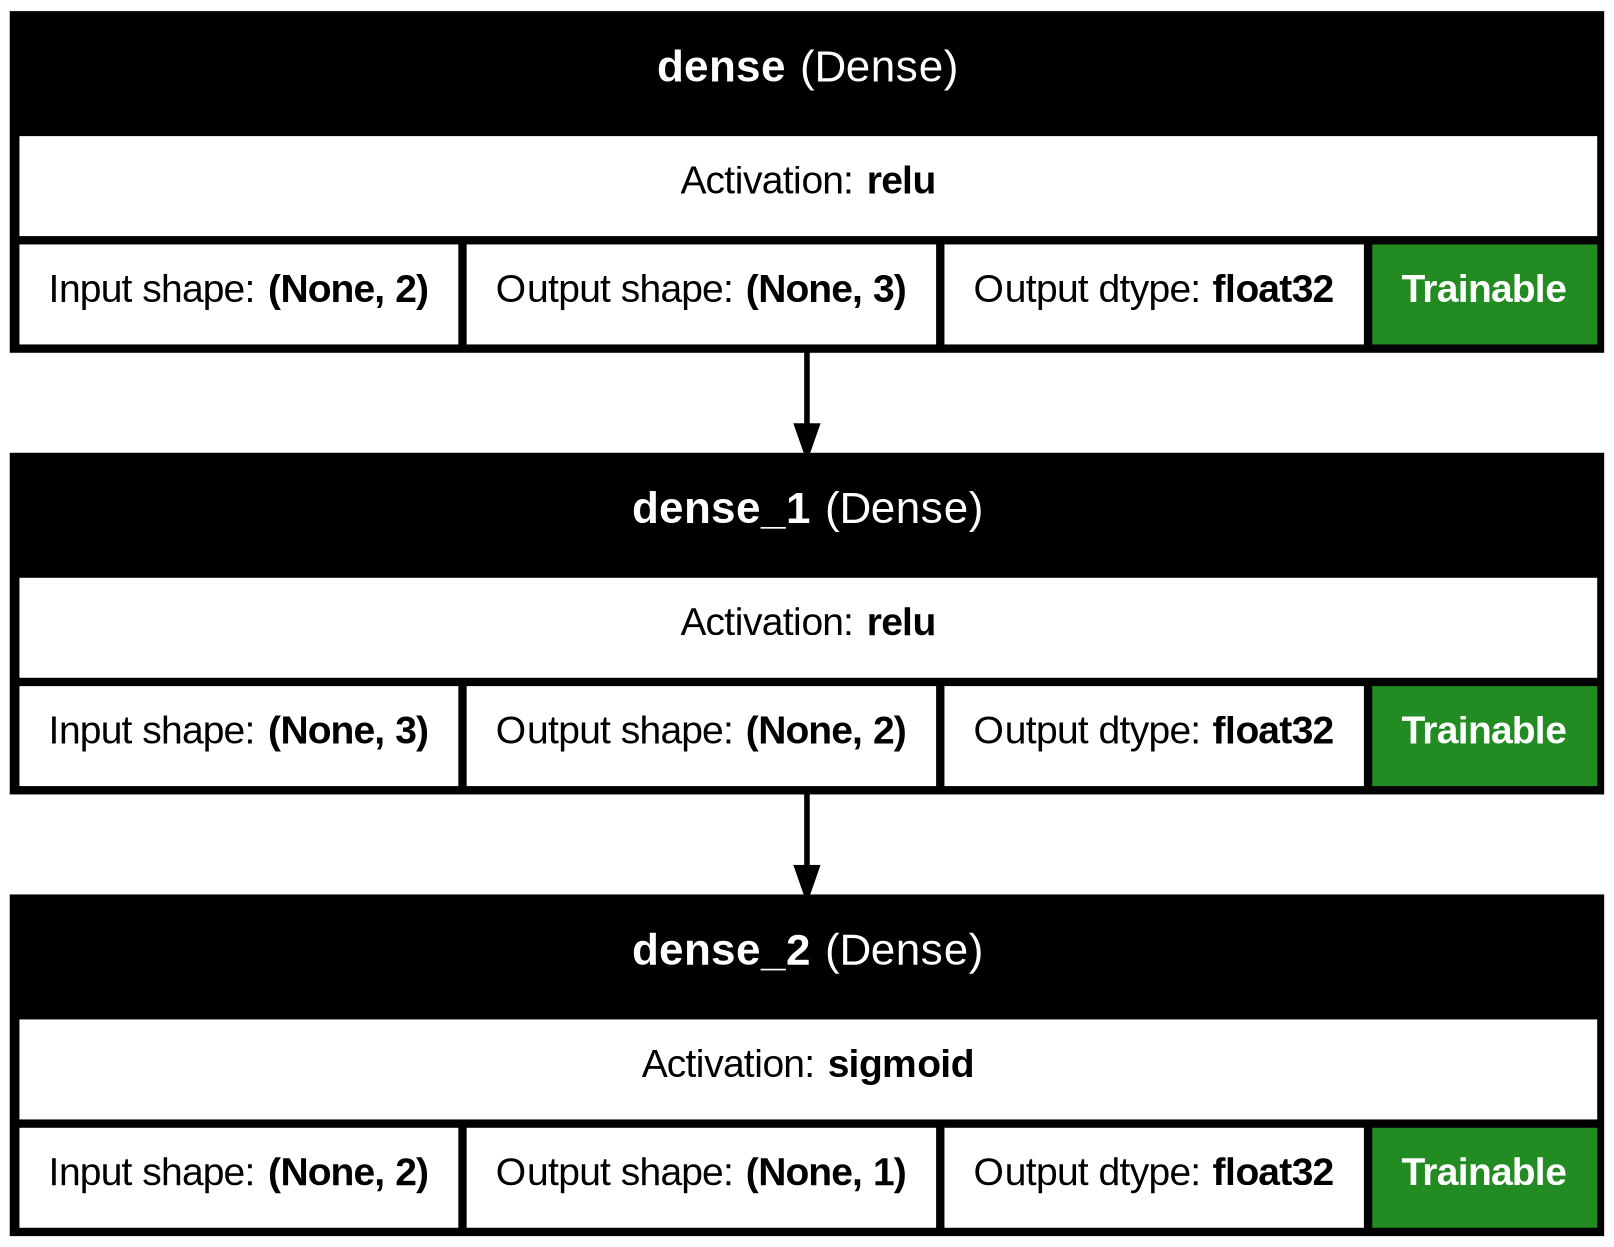

In [9]:
plot_model(model,to_file='plot_model.png', show_shapes=True,
    show_dtype=True,
    show_layer_names=True,
    expand_nested=True,
    show_layer_activations=True,
    show_trainable=True)

In [10]:
model.compile(loss = 'binary_crossentropy',optimizer = 'adam',metrics=['accuracy'])
history1 = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.5125 - loss: 0.6986 - val_accuracy: 0.6000 - val_loss: 0.7053
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5125 - loss: 0.6983 - val_accuracy: 0.4000 - val_loss: 0.7049
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5375 - loss: 0.6980 - val_accuracy: 0.3500 - val_loss: 0.7048
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5375 - loss: 0.6978 - val_accuracy: 0.3500 - val_loss: 0.7046
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5375 - loss: 0.6977 - val_accuracy: 0.3500 - val_loss: 0.7043
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5375 - loss: 0.6974 - val_accuracy: 0.3500 - val_loss: 0.7040
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5375 - loss: 0.6973 - val_accuracy: 0.3500 - val_loss: 0.7038
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5375 - loss: 0.6970 - val_accuracy: 0.3500 - val_loss

> got val_accuracy: 0.4500 which is so less

# With batch normalization

In [11]:
model2 = Sequential()

model2.add(Dense(3,input_dim = 2, activation='relu'))
model2.add(BatchNormalization()) #batch norm
model2.add(Dense(2,activation='relu'))
model2.add(BatchNormalization())
model2.add(Dense(1,activation='sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62 (252.00 B)

 Trainable params: 20 (80.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 42 (172.00 B)

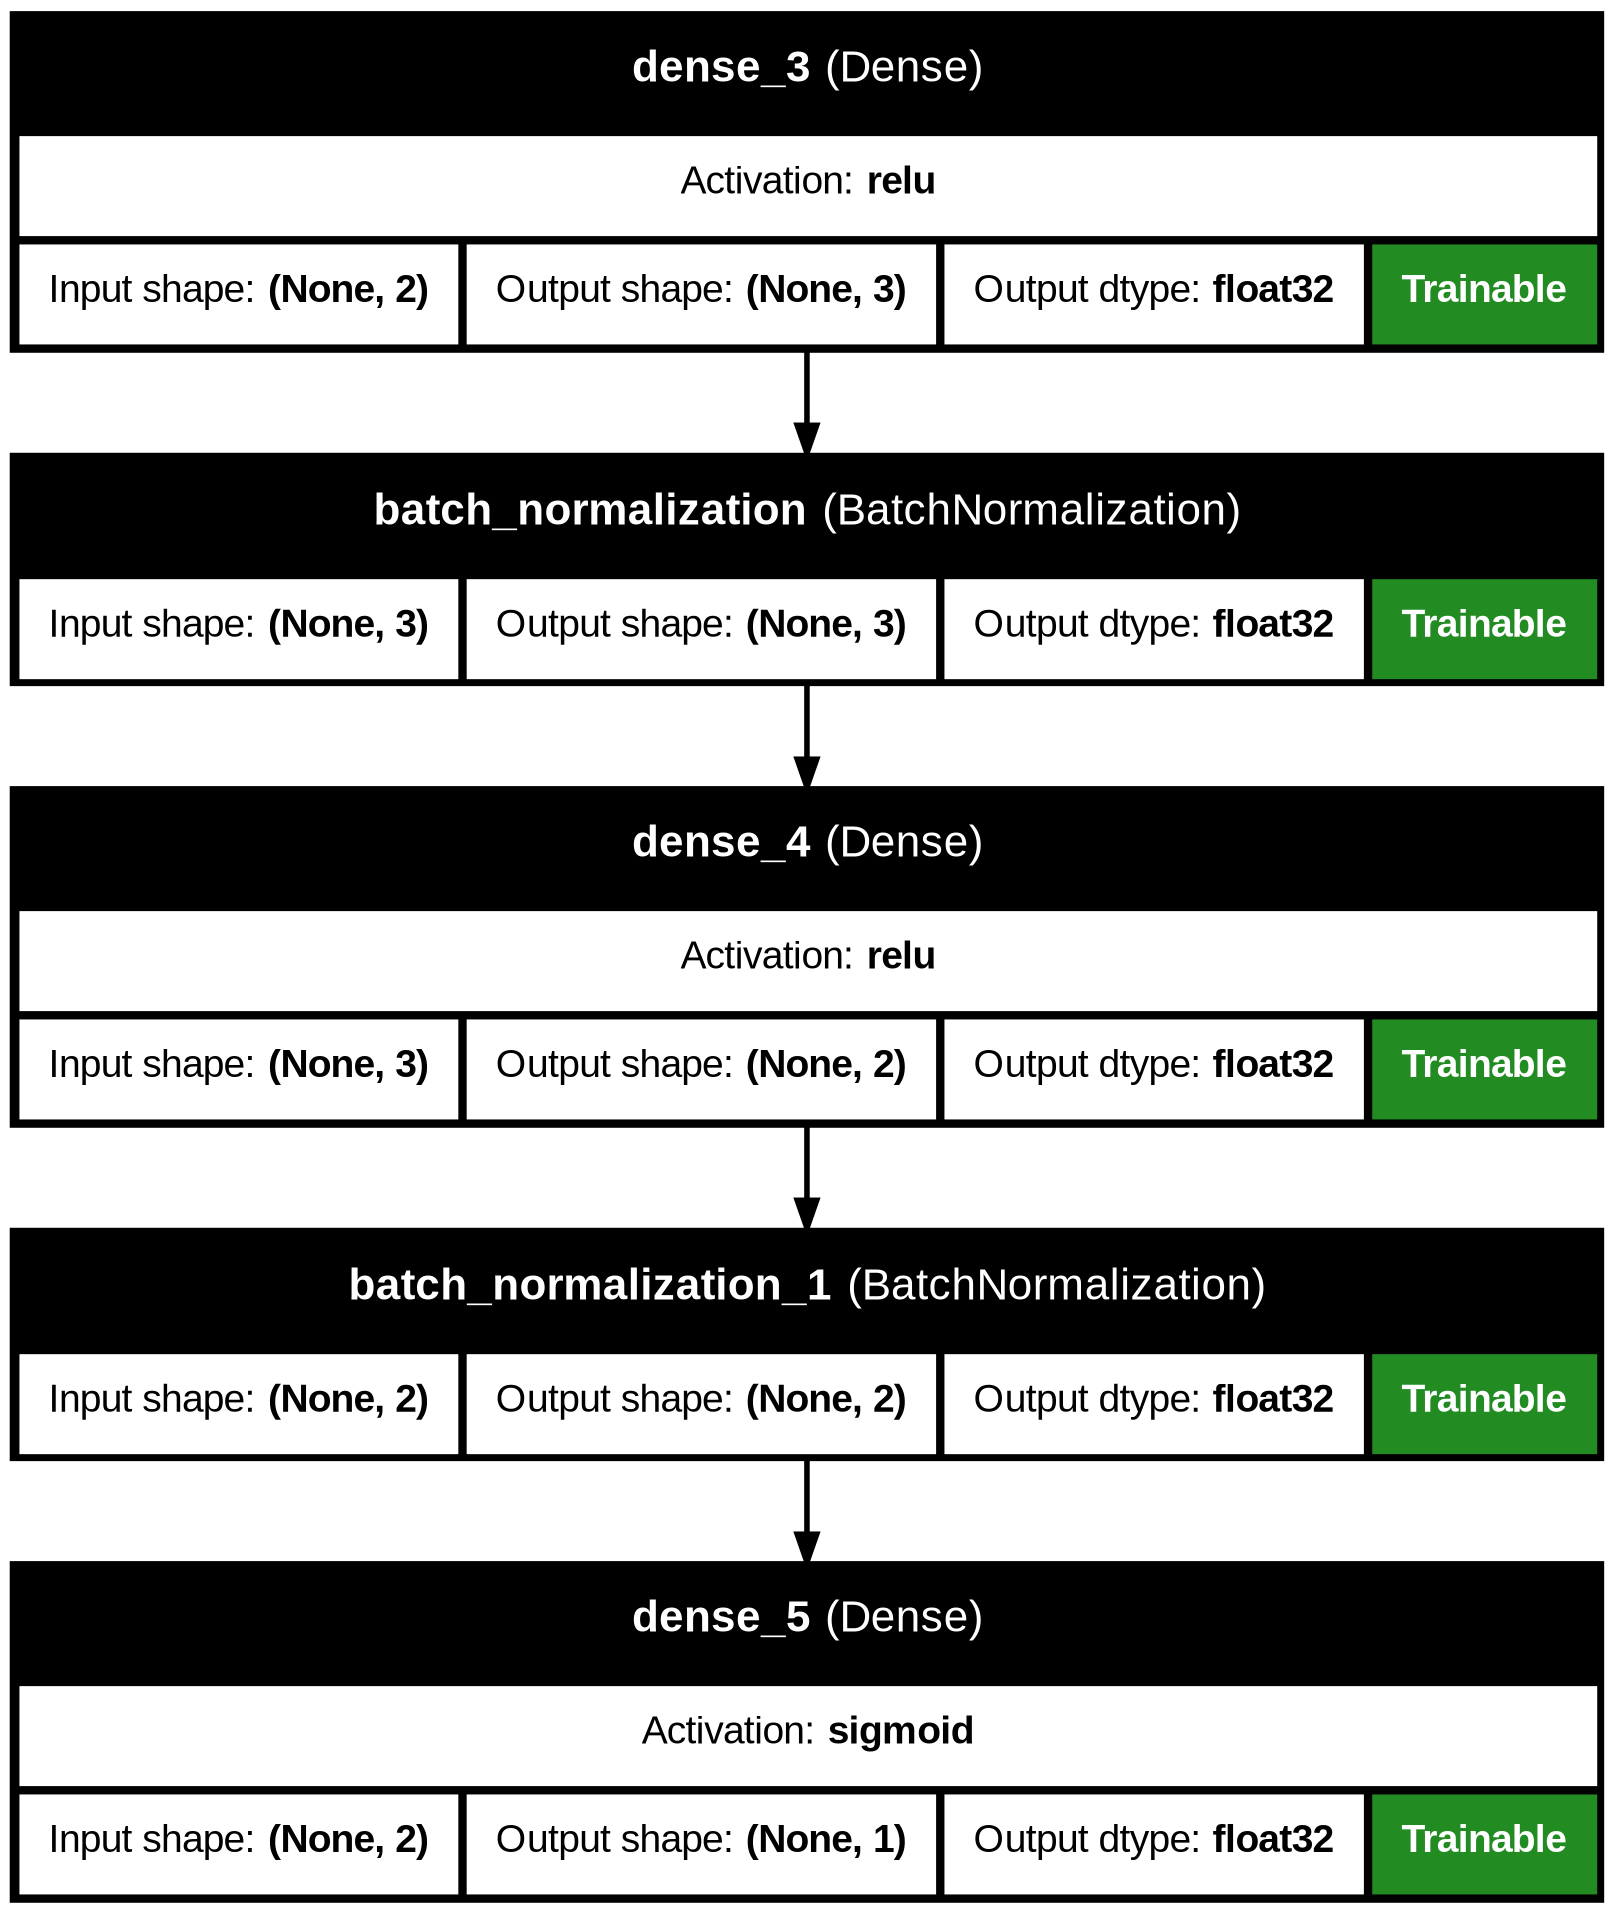

In [12]:
plot_model(model2,to_file='plot_model2.png', show_shapes=True,
    show_dtype=True,
    show_layer_names=True,
    expand_nested=True,
    show_layer_activations=True,
    show_trainable=True)

In [13]:
model2.compile(loss = 'binary_crossentropy',optimizer = 'adam',metrics=['accuracy'])
history2 = model2.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step - accuracy: 0.7000 - loss: 0.6725 - val_accuracy: 0.5500 - val_loss: 0.6925
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7000 - loss: 0.6602 - val_accuracy: 0.5500 - val_loss: 0.6910
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6625 - loss: 0.6976 - val_accuracy: 0.5500 - val_loss: 0.6894
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.6250 - loss: 0.6956 - val_accuracy: 0.6500 - val_loss: 0.6881
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6750 - loss: 0.6566 - val_accuracy: 0.6500 - val_loss: 0.6867
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6750 - loss: 0.6809 - val_accuracy: 0.6500 - val_loss: 0.6853
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7000 - loss: 0.6403 - val_accuracy: 0.6500 - val_loss: 0.6838
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6750 - loss: 0.6686 - val_accuracy: 0.6500 - val_loss

got val_accuracy: 0.6000 after using Batch Norm

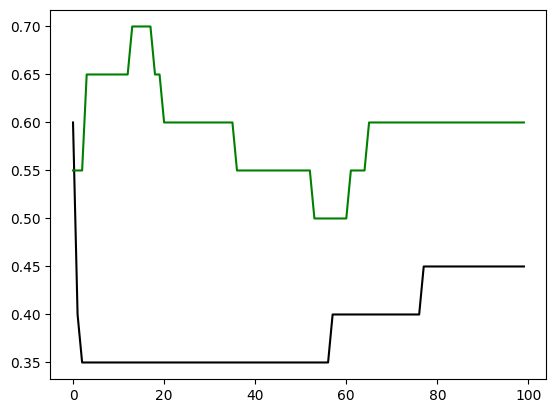

In [14]:
plt.plot(history1.history['val_accuracy'],color='black') # without BN
plt.plot(history2.history['val_accuracy'],color='green') # with BN

In [15]:
# Based on the validation accuracy plot:
# 1. The model with Batch Normalization (green curve) converges significantly faster and achieves a higher validation accuracy (~60%) within the first few epochs.
# 2. The model without Batch Normalization (black curve) trains much slower and struggles to break past ~45% validation accuracy, showcasing how Batch Normalization helps in stabilizing and accelerating training.